# Hypothesis testing: Iowa liquor sales 2025 × county demographics

**Purpose.** Look at the data first, let the patterns in it suggest which hypotheses are worth testing,
then test only those — keeping the ones the data supports, so the final report states hypotheses that
are *specific, measurable and defensible*.

**Unit of analysis.** Iowa county (n = 99). The census variables only vary by county, so transactions are
aggregated to one row per county before any EDA or test (testing on 2.5M rows would inflate significance
with 2.5M copies of 99 census values).

**Workflow.**
1. **EDA (section 2)** — descriptive statistics, distributions, category mix and group comparisons on the
   full year, using only standard exploratory techniques (no modelling yet).
2. **Pattern detection (end of section 2)** — rank every predictor × outcome pair by absolute Spearman
   correlation; the strongest pairs become the candidate hypotheses.
3. **Candidate hypotheses (section 3)** — every candidate tested below is either one of these
   EDA-detected patterns, or one of the 3 still-usable hypotheses from the pre-submission draft (kept
   for continuity), each written as a falsifiable statement with a direction and confounder controls,
   fixed **before** any significance test is run.
4. **Screening** on Jan–Jun 2025 → candidates must pass with Holm-adjusted p < 0.05.
5. **Confirmation** on Jul–Dec 2025 (purchases the screening never saw) → same direction, Holm-adjusted p < 0.05.
6. **Robustness** on the full year → bootstrap CI, dropping influential counties, population-weighted fit.

Each hypothesis therefore rests on several lines of evidence: a rank correlation with a permutation test,
a regression with controls, replication in a second period, and robustness checks.

**On using full-year EDA to spot a pattern and then "confirming" it on half of that same year:** this is a
real limitation, not eliminated by the split — a pattern visible across the whole year is, by construction,
visible in at least one half. What the split **does** still guard against is a pattern that is an artefact of
one half only (e.g. the duplicated download part, or a metric only defined in one period): a candidate must
independently clear Holm-corrected significance in **both** Jan–Jun and Jul–Dec, in the same direction, or
it is dropped. State this caveat in the report alongside the others in section 10.

**Input.** `data/processed/iowa_liquor_sales_2025_census_integrated.csv` (SSOT, built by `scripts/join_datasets.py`).
Exact duplicates (`is_exact_duplicate == 1`) and the 1,308 rows with no county are excluded.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SSOT = ROOT / "data/processed/iowa_liquor_sales_2025_census_integrated.csv"
COUNTY_CENSUS = ROOT / "data/processed/census_iowa_counties.csv"
FEATURES = ROOT / "data/processed/county_features_2025.csv"

ALPHA = 0.05
N_PERM = 5000
N_BOOT = 2000
SEED = 2025
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

## 1. Build county-level features

One row per county × period (`H1` = Jan–Jun, `H2` = Jul–Dec, `FY` = full year). Definitions:

| Feature | Definition |
|---|---|
| `liters_per_adult` | liters sold ÷ population 21+ (annualised: half-year values × 2) |
| `premium_share` | share of liters with price per liter in the statewide top quartile (liter-weighted cut-off) |
| `value_share` | share of liters with price per liter in the statewide bottom quartile |
| `small_bottle_share` | share of **bottles** that are ≤ 375 ml (50, 100, 200, 375 ml) |
| `handle_share` | share of liters sold in 1.75 L bottles |
| `agave_share`, `whiskey_share`, `vodka_share`, `rtd_share` | share of liters in that category family |
| `stores_per_10k_adults` | distinct licensed stores buying from ABD ÷ (population 21+ / 10,000) |
| `lines_per_capita` | invoice lines (rows) ÷ total population |

**Liters are recomputed as `sales_bottles × bottle_volume_ml / 1000`.** In Nov–Dec 2025 the source truncates
`sales_liters` to whole numbers (every 50 ml mini shows 0 L, and Nov–Dec liters are understated by 3.4%);
Jan–Oct values match the recomputed ones.

Price per liter = `sales_dollars / liters`, which exists for all 12 months, so the blank
`state_bottle_retail` column for Jan–Jun does not block the price-tier analysis. Returns (negative
liters/dollars) count towards volume totals but are left out of price and share calculations.

Building reads the 1.1 GB SSOT once (about 1 minute); the result is cached in `data/processed/county_features_2025.csv`.

In [2]:
LIQ_COLS = ["ordered_on", "store_no", "county_fips_code", "category_name", "bottle_volume_ml",
            "sales_bottles", "sales_dollars", "county_name", "is_exact_duplicate"]


def family(cat):
    c = str(cat).upper()
    if any(k in c for k in ("LIQUEUR", "SCHNAPPS", "CORDIAL", "TRIPLE SEC")):
        return "liqueur"            # includes whiskey liqueurs (e.g. cinnamon whisky)
    if "VODKA" in c:
        return "vodka"
    if any(k in c for k in ("WHISK", "BOURBON", "SCOTCH")):
        return "whiskey"
    if "RUM" in c:
        return "rum"
    if "TEQUILA" in c or "MEZCAL" in c:
        return "agave"
    if "GIN" in c:
        return "gin"
    if "BRAND" in c:
        return "brandy"
    if "COCKTAIL" in c:
        return "rtd"
    return "other"


def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, w = np.asarray(values)[order], np.asarray(weights)[order]
    cum = np.cumsum(w) / w.sum()
    return float(v[np.searchsorted(cum, q)])


def build_features():
    liq = pd.read_csv(SSOT, usecols=LIQ_COLS, dtype={"county_fips_code": "string", "store_no": "string"})
    n_raw = len(liq)
    liq = liq[(liq.is_exact_duplicate == 0) & liq.county_fips_code.notna()].copy()
    print(f"rows: {n_raw:,} in SSOT -> {len(liq):,} after removing duplicates and rows without a county")
    liq["period"] = np.where(pd.to_datetime(liq.ordered_on).dt.month <= 6, "H1", "H2")
    liq["family"] = liq.category_name.map(family)
    liq["sales_liters"] = liq.sales_bottles * liq.bottle_volume_ml / 1000  # source truncates Nov-Dec liters

    pos = (liq.sales_liters > 0) & (liq.sales_dollars > 0) & (liq.sales_bottles > 0)
    liq["ppl"] = np.where(pos, liq.sales_dollars / liq.sales_liters.where(pos), np.nan)
    lo = weighted_quantile(liq.ppl[pos], liq.sales_liters[pos], 0.25)
    hi = weighted_quantile(liq.ppl[pos], liq.sales_liters[pos], 0.75)
    print(f"price tiers (USD per liter, liter-weighted): value <= {lo:.2f}, premium >= {hi:.2f}")

    p = liq[pos]
    rows = []
    for period, months in (("H1", 6), ("H2", 6), ("FY", 12)):
        d = liq if period == "FY" else liq[liq.period == period]
        dp = p if period == "FY" else p[p.period == period]
        g, gp = d.groupby("county_fips_code"), dp.groupby("county_fips_code")
        L = gp.sales_liters.sum()
        share = lambda mask, col="sales_liters": dp[mask].groupby("county_fips_code")[col].sum().reindex(L.index, fill_value=0)
        f = pd.DataFrame({
            "county_name": g.county_name.agg(lambda s: s.mode().iat[0]).str.title(),
            "liters": g.sales_liters.sum(),
            "dollars": g.sales_dollars.sum(),
            "lines": g.size(),
            "stores": g.store_no.nunique(),
            "premium_liters": share(dp.ppl >= hi),
            "value_liters": share(dp.ppl <= lo),
        })
        f["premium_share"] = f.premium_liters / L
        f["value_share"] = f.value_liters / L
        f["small_bottle_share"] = share(dp.bottle_volume_ml <= 375, "sales_bottles") / gp.sales_bottles.sum()
        f["handle_share"] = share(dp.bottle_volume_ml == 1750) / L
        for fam in ("agave", "whiskey", "vodka", "rtd"):
            f[f"{fam}_share"] = share(dp.family == fam) / L
        f["annualise"] = 12 / months
        f["period"] = period
        rows.append(f.reset_index())
    feats = pd.concat(rows, ignore_index=True)
    feats.attrs["tiers"] = (lo, hi)
    return feats


if FEATURES.exists() and FEATURES.stat().st_mtime > SSOT.stat().st_mtime:
    liq_feats = pd.read_csv(FEATURES, dtype={"county_fips_code": "string"})
    print(f"loaded cached features: {FEATURES.name}")
else:
    liq_feats = build_features()
    liq_feats.to_csv(FEATURES, index=False)
    print(f"wrote {FEATURES.name}")

loaded cached features: county_features_2025.csv


In [3]:
census = pd.read_csv(COUNTY_CENSUS, dtype={"county_fips_code": "string"})
df = liq_feats.merge(census, on="county_fips_code", how="inner", validate="many_to_one")

a = df.annualise
df["liters_per_adult"] = df.liters * a / df.cty_population_21_plus
df["log_liters_per_adult"] = np.log(df.liters_per_adult)
df["log_lines_per_capita"] = np.log(df.lines * a / df.cty_total_population)
df["log_premium_liters_per_adult"] = np.log(df.premium_liters * a / df.cty_population_21_plus)
df["log_value_liters_per_adult"] = np.log(df.value_liters * a / df.cty_population_21_plus)
df["stores_per_10k_adults"] = df.stores / df.cty_population_21_plus * 1e4
df["log_population"] = np.log(df.cty_total_population)
df["income_k"] = df.cty_median_household_income / 1000

P = {p: d.set_index("county_fips_code") for p, d in df.groupby("period")}
assert all(len(d) == 99 for d in P.values()), "expected all 99 counties in every period"
print({p: len(d) for p, d in P.items()}, "counties per period")

{'FY': 99, 'H1': 99, 'H2': 99} counties per period


## 2. Exploratory data analysis (EDA)

Standard, course-level EDA only — sanity checks, descriptive statistics, distribution plots, category-mix
bar charts, group comparisons and a correlation heatmap. No modelling here. The section ends with a
**pattern-detection** step that ranks every predictor × outcome pair by correlation strength; the
candidate hypotheses in section 3 are drawn from that ranking.

In [4]:
fy = P["FY"]
checks = pd.Series({
    "counties": len(fy),
    "liters (FY) = H1 + H2": np.isclose(fy.liters.sum(), P["H1"].liters.sum() + P["H2"].liters.sum()),
    "shares within [0, 1]": bool(((fy.filter(like="_share") >= 0) & (fy.filter(like="_share") <= 1)).all().all()),
    "no missing outcomes": not fy.filter(regex="share|log_").isna().any().any(),
    "statewide liters per adult (FY)": round(fy.liters.sum() / fy.cty_population_21_plus.sum(), 2),
})
checks

counties                             99
liters (FY) = H1 + H2              True
shares within [0, 1]               True
no missing outcomes                True
statewide liters per adult (FY)    9.51
dtype: object

In [5]:
show = ["liters_per_adult", "premium_share", "value_share", "small_bottle_share", "handle_share",
        "agave_share", "rtd_share", "stores_per_10k_adults",
        "cty_median_household_income", "cty_poverty_rate", "cty_unemployment_rate",
        "cty_pct_bachelors_or_higher", "cty_pct_hispanic", "cty_median_age", "cty_total_population"]
fy[show].describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
liters_per_adult,7.107,3.265,1.351,6.900,22.653
premium_share,0.216,0.039,0.136,0.213,0.321
value_share,0.266,0.035,0.182,0.259,0.363
small_bottle_share,0.387,0.096,0.177,0.392,0.680
handle_share,0.444,0.079,0.222,0.450,0.612
agave_share,0.035,0.016,0.011,0.031,0.088
rtd_share,0.037,0.012,0.015,0.036,0.083
stores_per_10k_adults,10.756,2.647,4.887,10.223,18.868
cty_median_household_income,71592.303,8474.298,54934.000,71223.000,102379.000
cty_poverty_rate,10.689,2.956,5.140,10.140,18.240


In [6]:
top = fy.sort_values("liters_per_adult", ascending=False)[["county_name", "liters_per_adult", "stores_per_10k_adults", "cty_total_population"]]
print("Highest and lowest liters per adult (FY) - extremes to keep in mind (tourism, college towns, border stores):")
pd.concat([top.head(5), top.tail(5)])

Highest and lowest liters per adult (FY) - extremes to keep in mind (tourism, college towns, border stores):


,county_name,liters_per_adult,stores_per_10k_adults,cty_total_population
county_fips_code,,,,
19059,Dickinson,22.653,16.008,17990
19045,Clinton,16.045,9.320,46268
19033,Cerro Gordo,15.144,10.236,42632
19153,Polk,12.971,8.536,503175
19027,Carroll,12.289,11.991,20594
19053,Decatur,2.432,9.181,7759
19071,Fremont,2.205,8.050,6514
19173,Taylor,2.047,11.457,5868
19115,Louisa,1.998,10.092,10678


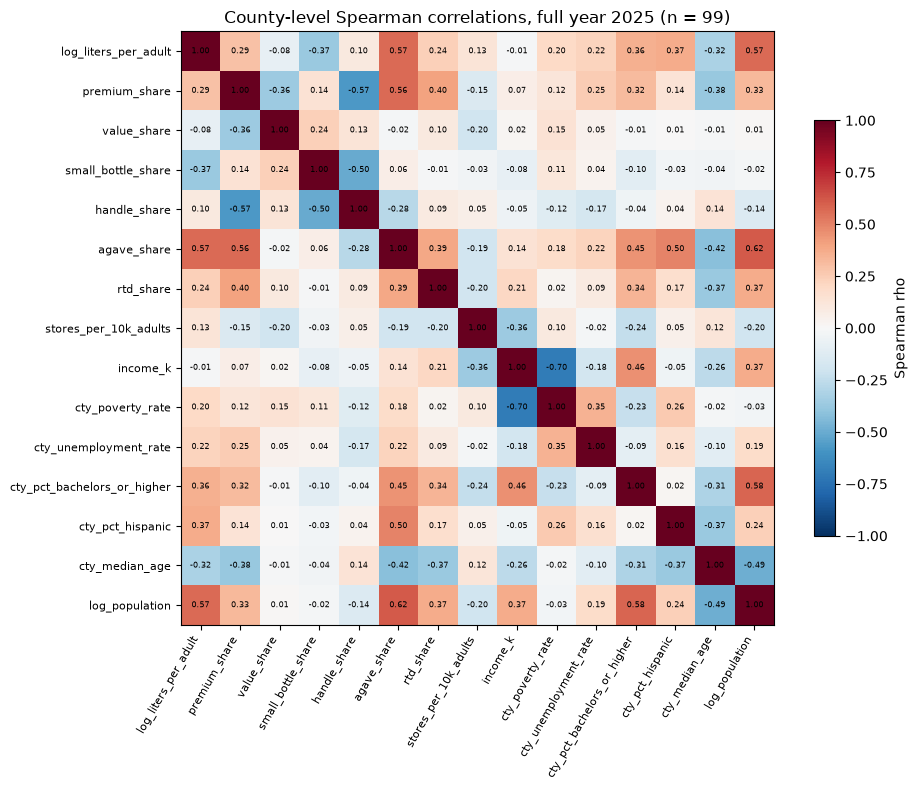

In [7]:
corr_vars = ["log_liters_per_adult", "premium_share", "value_share", "small_bottle_share", "handle_share",
             "agave_share", "rtd_share", "stores_per_10k_adults", "income_k", "cty_poverty_rate",
             "cty_unemployment_rate", "cty_pct_bachelors_or_higher", "cty_pct_hispanic", "cty_median_age", "log_population"]
C = fy[corr_vars].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C)), C.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(C)), C.columns, fontsize=8)
for i in range(len(C)):
    for j in range(len(C)):
        ax.text(j, i, f"{C.iat[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, shrink=0.7, label="Spearman rho")
ax.set_title("County-level Spearman correlations, full year 2025 (n = 99)")
plt.tight_layout()

In [8]:
# Pattern detection: rank every predictor x outcome pair by |Spearman rho| (full year, no controls yet).
# This is the step that turns "look at the data" into "which hypotheses are worth writing down".
outcome_cols = ["log_liters_per_adult", "log_lines_per_capita", "premium_share", "value_share",
                "small_bottle_share", "handle_share", "agave_share", "whiskey_share", "vodka_share", "rtd_share"]
predictor_cols = ["log_population", "income_k", "cty_poverty_rate", "cty_unemployment_rate",
                   "cty_pct_bachelors_or_higher", "cty_pct_hispanic", "cty_median_age", "stores_per_10k_adults"]

pairs = [dict(outcome=o, predictor=p, rho=stats.spearmanr(fy[p], fy[o])[0])
         for o in outcome_cols for p in predictor_cols]
pattern = pd.DataFrame(pairs).assign(abs_rho=lambda d: d.rho.abs()).sort_values("abs_rho", ascending=False)
print("Strongest predictor -> outcome patterns detected in the full-year EDA:")
pattern.drop(columns="abs_rho").head(12).reset_index(drop=True)

Strongest predictor -> outcome patterns detected in the full-year EDA:


,outcome,predictor,rho
0,whiskey_share,log_population,-0.661
1,agave_share,log_population,0.616
2,log_liters_per_adult,log_population,0.567
3,agave_share,cty_pct_hispanic,0.499
4,agave_share,cty_pct_bachelors_or_higher,0.451
5,agave_share,cty_median_age,-0.421
6,whiskey_share,cty_pct_bachelors_or_higher,-0.421
7,log_lines_per_capita,log_population,0.400
8,premium_share,cty_median_age,-0.375
9,rtd_share,log_population,0.373


**Distributions, category mix and the population effect.** Before turning the ranked patterns above into
formal hypotheses, a closer look at the shape of the data: how skewed the outcome variables are
(motivating the log transforms used in the OLS models later), how category mix varies across counties,
and how the two strongest patterns found (population size, % Hispanic) look once counties are split
into rural / mid-size / urban groups by population.

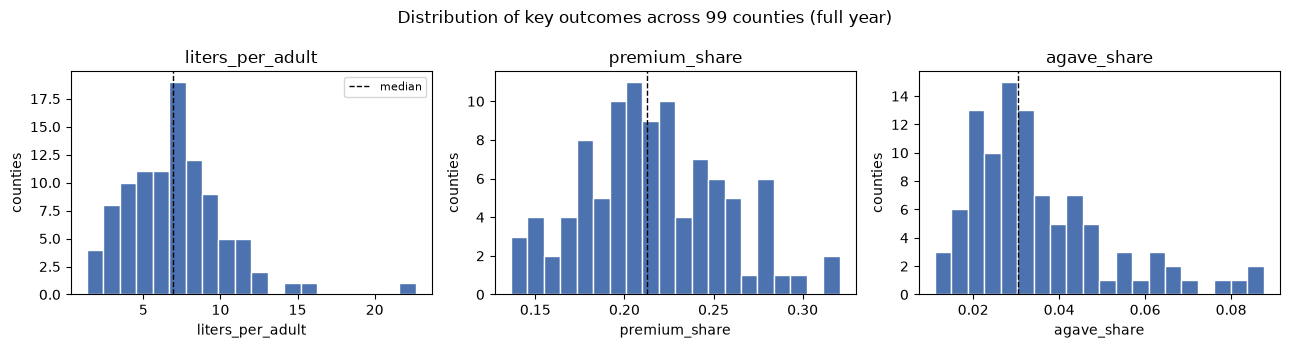

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["liters_per_adult", "premium_share", "agave_share"]):
    ax.hist(fy[col], bins=20, color="#4C72B0", edgecolor="white")
    ax.axvline(fy[col].median(), color="black", lw=1, ls="--", label="median")
    ax.set(title=col, xlabel=col, ylabel="counties")
axes[0].legend(fontsize=8)
fig.suptitle("Distribution of key outcomes across 99 counties (full year)")
plt.tight_layout()

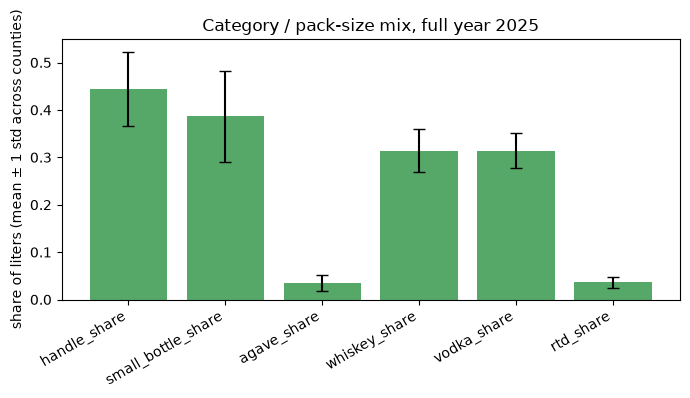

In [10]:
fam_cols = ["handle_share", "small_bottle_share", "agave_share", "whiskey_share", "vodka_share", "rtd_share"]
fam_mean, fam_std = fy[fam_cols].mean(), fy[fam_cols].std()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(fam_cols, fam_mean, yerr=fam_std, capsize=4, color="#55A868")
ax.set(ylabel="share of liters (mean ± 1 std across counties)", title="Category / pack-size mix, full year 2025")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()

,liters_per_adult,log_lines_per_capita,agave_share,cty_pct_hispanic
pop_tertile,,,,
rural,5.203,-0.681,0.025,5.009
mid-size,7.125,-0.436,0.032,5.406
urban,8.992,-0.299,0.049,7.497


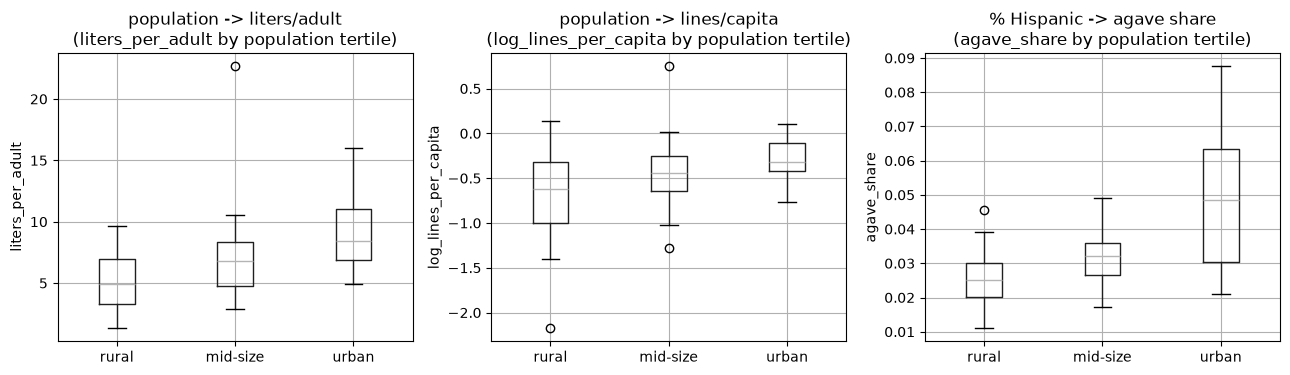

In [11]:
fy = fy.assign(pop_tertile=pd.qcut(fy.cty_total_population, 3, labels=["rural", "mid-size", "urban"]))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (label, col) in zip(axes, [("population -> liters/adult", "liters_per_adult"),
                                    ("population -> lines/capita", "log_lines_per_capita"),
                                    ("% Hispanic -> agave share", "agave_share")]):
    fy.boxplot(column=col, by="pop_tertile", ax=ax)
    ax.set(title=f"{label}\n({col} by population tertile)", xlabel="", ylabel=col)
plt.suptitle("")
plt.tight_layout()
fy.groupby("pop_tertile")[["liters_per_adult", "log_lines_per_capita", "agave_share", "cty_pct_hispanic"]].mean().round(3)

## 3. Candidate hypotheses (fixed before testing)

Every candidate below is either (a) one of the **EDA-detected patterns** ranked at the end of section 2 —
the predictor × outcome pairs with the strongest Spearman correlation, now written as a falsifiable
statement with a direction and confounder controls — or (b) one of the 3 still-usable hypotheses from
the pre-submission draft (v3), kept for continuity and operationalised as literally as possible.
`O1`, `O3`, `O4` are the originals; `N1`–`N11` are the EDA-derived candidates, drawn from the strongest
rows of the pattern-detection table (population size and % Hispanic lead it, followed by income,
poverty, unemployment, education and age — all worth testing even though several of them turn out not
to replicate below).

`N10` and `N11` are added specifically for two stakeholders beyond ABD's overall stocking plan: `N10`
targets ABD's **category-mix** recommendation directly (rural vs. urban whiskey share is the single
strongest pattern in the whole table, ρ = −0.66, yet no earlier candidate tested a mix outcome against
population); `N11` targets **retailers' assortment planning** (does the urbanisation effect behind the
rejected age→RTD hypothesis `N7` actually show up once population itself is the predictor?).

Known weaknesses of the originals that the EDA-derived candidates try to fix:
- **O1** mixes *how much* a county buys with *what* it buys: richer or more urban counties can buy more premium liters simply because they buy more of everything. `N1` tests the **mix** (premium share) instead — notably, this mix pattern is *not* among the strong rows of the pattern-detection table, which is itself informative.
- **O2** ("% aged 21+ → liters sold per square mile") is not tested: it needs county land area, which came from the Census Gazetteer, a source this project no longer uses. Its outcome was also mechanically driven by population density.
- Population **density** (also from the Gazetteer) is replaced by county **population size**, which the ACS provides and which both the pattern-detection ranking and the tertile comparison in section 2 flag as the strongest driver in the data.
- **O3** "transactions" are store orders to ABD, not consumer purchases, and orders per capita depend on how many stores a county has.
- **O4** same volume vs mix issue as O1; `N4` uses value share.

In [12]:
CANDIDATES = pd.DataFrame([
    # id, statement, predictor x, outcome y, direction, controls
    ("O1", "Higher median income -> more premium liters per adult",            "income_k",                    "log_premium_liters_per_adult", +1, ["log_population"]),
    ("O3", "Larger county population -> more transactions (lines) per capita",  "log_population",                "log_lines_per_capita",         +1, ["income_k"]),
    ("O4", "Higher unemployment -> more value-tier liters per adult",           "cty_unemployment_rate",       "log_value_liters_per_adult",   +1, ["log_population"]),
    ("N1", "Higher median income -> higher premium share of liters",           "income_k",                    "premium_share",                +1, ["log_population"]),
    ("N2", "Higher % bachelor's degree -> higher premium share of liters",     "cty_pct_bachelors_or_higher", "premium_share",                +1, ["log_population"]),
    ("N3", "Higher poverty rate -> higher share of small bottles (<=375 ml)",  "cty_poverty_rate",            "small_bottle_share",           +1, ["log_population"]),
    ("N4", "Higher unemployment -> higher value-tier share of liters",         "cty_unemployment_rate",       "value_share",                  +1, ["log_population"]),
    ("N5", "Higher % Hispanic -> higher tequila/mezcal share of liters",       "cty_pct_hispanic",            "agave_share",                  +1, ["log_population", "income_k"]),
    ("N6", "More stores per adult -> more liters per adult (availability)",    "stores_per_10k_adults",       "log_liters_per_adult",         +1, ["log_population", "income_k"]),
    ("N7", "Older median age -> lower ready-to-drink (RTD) share of liters",   "cty_median_age",              "rtd_share",                    -1, ["log_population", "income_k"]),
    ("N8", "Larger county population -> more liters per adult",                "log_population",                "log_liters_per_adult",         +1, ["income_k"]),
    ("N9", "Higher median income -> lower 1.75 L 'handle' share of liters",    "income_k",                    "handle_share",                 -1, ["log_population"]),
    ("N10", "Smaller county population -> higher whiskey share of liters (stocking mix, for ABD)",   "log_population", "whiskey_share", -1, ["income_k"]),
    ("N11", "Larger county population -> higher ready-to-drink (RTD) share of liters (assortment mix, for retailers)", "log_population", "rtd_share", +1, ["income_k"]),
], columns=["id", "statement", "x", "y", "sign", "controls"]).set_index("id")
CANDIDATES[["statement", "x", "y", "sign"]]

,statement,x,y,sign
id,,,,
O1,Higher median income -> more premium liters per adult,income_k,log_premium_liters_per_adult,1
O3,Larger county population -> more transactions (lines) per capita,log_population,log_lines_per_capita,1
O4,Higher unemployment -> more value-tier liters per adult,cty_unemployment_rate,log_value_liters_per_adult,1
N1,Higher median income -> higher premium share of liters,income_k,premium_share,1
N2,Higher % bachelor's degree -> higher premium share of liters,cty_pct_bachelors_or_higher,premium_share,1
N3,Higher poverty rate -> higher share of small bottles (<=375 ml),cty_poverty_rate,small_bottle_share,1
N4,Higher unemployment -> higher value-tier share of liters,cty_unemployment_rate,value_share,1
N5,Higher % Hispanic -> higher tequila/mezcal share of liters,cty_pct_hispanic,agave_share,1
N6,More stores per adult -> more liters per adult (availability),stores_per_10k_adults,log_liters_per_adult,1


## 4. Test procedure

For each candidate and period:
1. **Spearman ρ** between predictor and outcome, with a one-sided **permutation p-value** (5,000 shuffles; no normality assumption).
2. **OLS with controls** on z-scored variables (so β is a standardised effect), **HC3 robust** standard errors, one-sided p-value in the hypothesised direction.

A candidate counts as significant in a period only if **both** tests agree (Holm-adjusted across candidates).

In [13]:
rng = np.random.default_rng(SEED)
z = lambda s: (s - s.mean()) / s.std(ddof=0)


def perm_spearman(x, y, sign, n=N_PERM):
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    rx, ry = (rx - rx.mean()) / rx.std(), (ry - ry.mean()) / ry.std()
    rho = float(np.mean(rx * ry))
    perm = np.array([np.mean(rng.permutation(rx) * ry) for _ in range(n)])
    p = (1 + np.sum(sign * perm >= sign * rho)) / (n + 1)
    return rho, p


def ols(d, x, y, controls, weights=None):
    X = sm.add_constant(d[[x] + controls].apply(z))
    model = sm.WLS(z(d[y]), X, weights=weights) if weights is not None else sm.OLS(z(d[y]), X)
    return model.fit(cov_type="HC3")


def one_sided(p_two, beta, sign):
    return p_two / 2 if np.sign(beta) == sign else 1 - p_two / 2


def run_tests(data, ids):
    out = []
    for cid in ids:
        c = CANDIDATES.loc[cid]
        d = data[[c.x, c.y] + c.controls].dropna()
        rho, p_rho = perm_spearman(d[c.x].values, d[c.y].values, c.sign)
        fit = ols(d, c.x, c.y, c.controls)
        beta = fit.params[c.x]
        out.append(dict(id=cid, n=len(d), rho=rho, p_rho=p_rho, beta=beta,
                        p_beta=one_sided(fit.pvalues[c.x], beta, c.sign), r2=fit.rsquared))
    res = pd.DataFrame(out).set_index("id")
    res["p_rho_holm"] = multipletests(res.p_rho, method="holm")[1]
    res["p_beta_holm"] = multipletests(res.p_beta, method="holm")[1]
    res["pass"] = (res.p_rho_holm < ALPHA) & (res.p_beta_holm < ALPHA)
    return res

## 5. Screening: Jan–Jun 2025

In [14]:
screen = run_tests(P["H1"], CANDIDATES.index)
screen.join(CANDIDATES.statement)

,n,rho,p_rho,beta,p_beta,r2,p_rho_holm,p_beta_holm,pass,statement
id,,,,,,,,,,
O1,99,0.007,4.641e-01,-0.224,9.985e-01,0.424,0.729,1.000e+00,False,Higher median income -> more premium liters per adult
O3,99,0.418,3.999e-04,0.472,5.477e-09,0.202,0.004,6.572e-08,True,Larger county population -> more transactions (lines) per capita
O4,99,0.200,2.320e-02,0.060,2.098e-01,0.333,0.162,1.000e+00,False,Higher unemployment -> more value-tier liters per adult
N1,99,0.076,2.284e-01,-0.037,6.264e-01,0.150,0.729,1.000e+00,False,Higher median income -> higher premium share of liters
N2,99,0.263,4.199e-03,0.162,1.194e-01,0.164,0.034,8.360e-01,False,Higher % bachelor's degree -> higher premium share of liters
N3,99,0.112,1.358e-01,0.095,1.916e-01,0.009,0.679,1.000e+00,False,Higher poverty rate -> higher share of small bottles (<=375 ml)
N4,99,0.088,1.936e-01,0.029,3.812e-01,0.010,0.729,1.000e+00,False,Higher unemployment -> higher value-tier share of liters
N5,99,0.499,2.000e-04,0.206,7.885e-04,0.633,0.003,7.885e-03,True,Higher % Hispanic -> higher tequila/mezcal share of liters
N6,99,0.152,6.719e-02,0.351,3.305e-04,0.463,0.403,3.636e-03,False,More stores per adult -> more liters per adult (availability)


## 6. Confirmation: Jul–Dec 2025 (only candidates that passed screening)

In [15]:
passed = screen.index[screen["pass"]].tolist()
print("carried forward:", passed)
confirm = run_tests(P["H2"], passed) if passed else pd.DataFrame()
confirm.join(CANDIDATES.statement)

carried forward: ['O3', 'N5', 'N8', 'N10', 'N11']


,n,rho,p_rho,beta,p_beta,r2,p_rho_holm,p_beta_holm,pass,statement
id,,,,,,,,,,
O3,99,0.396,2.000e-04,0.469,4.942e-09,0.198,9.998e-04,1.483e-08,True,Larger county population -> more transactions (lines) per capita
N5,99,0.467,2.000e-04,0.211,5.427e-05,0.599,9.998e-04,1.085e-04,True,Higher % Hispanic -> higher tequila/mezcal share of liters
N8,99,0.557,2.000e-04,0.634,2.108e-16,0.346,9.998e-04,8.431e-16,True,Larger county population -> more liters per adult
N10,99,-0.614,2.000e-04,-0.736,1.195e-24,0.479,9.998e-04,5.973e-24,True,"Smaller county population -> higher whiskey share of liters (stocking mix, f..."
N11,99,0.326,9.998e-04,0.268,4.285e-03,0.110,9.998e-04,4.285e-03,True,Larger county population -> higher ready-to-drink (RTD) share of liters (ass...


## 7. Robustness: full year

For candidates that replicated:
- **Bootstrap 95% CI** of the standardised β (resampling counties, 2,000 draws).
- **Influential counties removed**: refit without counties whose Cook's distance > 4/n.
- **Population-weighted** (WLS, weights = population 21+), so small counties with a single store do not dominate.

In [16]:
replicated = confirm.index[confirm["pass"]].tolist() if len(confirm) else []
rows = []
for cid in replicated:
    c = CANDIDATES.loc[cid]
    d = P["FY"][[c.x, c.y, "cty_population_21_plus", "county_name"] + c.controls].dropna()
    fit = ols(d, c.x, c.y, c.controls)
    boots = []
    for _ in range(N_BOOT):
        s = d.iloc[rng.integers(0, len(d), len(d))]
        boots.append(ols(s, c.x, c.y, c.controls).params[c.x])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    cooks = fit.get_influence().cooks_distance[0]
    keep = cooks <= 4 / len(d)
    fit_trim = ols(d[keep], c.x, c.y, c.controls)
    fit_w = ols(d, c.x, c.y, c.controls, weights=d.cty_population_21_plus)
    rows.append(dict(
        id=cid, beta_fy=fit.params[c.x], ci_low=lo, ci_high=hi,
        ci_excludes_0=bool(lo > 0 or hi < 0),
        dropped=", ".join(d.county_name[~keep]),
        beta_trimmed=fit_trim.params[c.x], p_trimmed=one_sided(fit_trim.pvalues[c.x], fit_trim.params[c.x], c.sign),
        beta_weighted=fit_w.params[c.x], p_weighted=one_sided(fit_w.pvalues[c.x], fit_w.params[c.x], c.sign),
    ))
robust = pd.DataFrame(rows).set_index("id") if rows else pd.DataFrame()
if len(robust):
    robust["robust"] = robust.ci_excludes_0 & (robust.p_trimmed < ALPHA) & (robust.p_weighted < ALPHA)
robust

,beta_fy,ci_low,ci_high,ci_excludes_0,dropped,beta_trimmed,p_trimmed,beta_weighted,p_weighted,robust
id,,,,,,,,,,
O3,0.471,0.343,0.600,True,"Davis, Decatur, Dickinson, Grundy, Keokuk",0.514,4.482e-10,0.368,2.543e-17,True
N5,0.209,0.090,0.330,True,"Adams, Black Hawk, Clinton, Crawford, Marshall, Scott, Sioux, Warren, Worth",0.259,2.372e-08,0.227,1.247e-02,True
N8,0.639,0.530,0.741,True,"Davis, Decatur, Dickinson, Louisa",0.682,2.542e-19,0.479,2.936e-26,True
N10,-0.765,-0.873,-0.637,True,"Mills, Polk, Sioux, Worth",-0.814,1.920e-43,-0.664,3.276e-11,True
N11,0.294,0.114,0.464,True,"Dallas, Linn, Polk, Wayne",0.354,3.135e-04,0.052,3.882e-01,False


## 8. Verdict for every candidate

In [17]:
def verdict(cid):
    if not screen.loc[cid, "pass"]:
        return "rejected at screening"
    if not confirm.loc[cid, "pass"]:
        return "did not replicate in Jul-Dec"
    if not robust.loc[cid, "robust"]:
        return "replicated, not robust"
    return "SUPPORTED"

summary = CANDIDATES[["statement"]].copy()
summary["rho_H1"] = screen.rho
summary["rho_H2"] = confirm.rho if len(confirm) else np.nan
summary["beta_FY"] = robust.beta_fy if len(robust) else np.nan
summary["95% CI"] = (robust.ci_low.round(2).astype(str) + " to " + robust.ci_high.round(2).astype(str)) if len(robust) else ""
summary["verdict"] = [verdict(i) for i in summary.index]
order = {"SUPPORTED": 0, "replicated, not robust": 1, "did not replicate in Jul-Dec": 2, "rejected at screening": 3}
summary["_o"], summary["_b"] = summary.verdict.map(order), -summary.beta_FY.abs().fillna(0)
summary.sort_values(["_o", "_b"]).drop(columns=["_o", "_b"])

,statement,rho_H1,rho_H2,beta_FY,95% CI,verdict
id,,,,,,
N10,"Smaller county population -> higher whiskey share of liters (stocking mix, f...",-0.666,-0.614,-0.765,-0.87 to -0.64,SUPPORTED
N8,Larger county population -> more liters per adult,0.573,0.557,0.639,0.53 to 0.74,SUPPORTED
O3,Larger county population -> more transactions (lines) per capita,0.418,0.396,0.471,0.34 to 0.6,SUPPORTED
N5,Higher % Hispanic -> higher tequila/mezcal share of liters,0.499,0.467,0.209,0.09 to 0.33,SUPPORTED
N11,Larger county population -> higher ready-to-drink (RTD) share of liters (ass...,0.367,0.326,0.294,0.11 to 0.46,"replicated, not robust"
O1,Higher median income -> more premium liters per adult,0.007,NaN,NaN,NaN,rejected at screening
O4,Higher unemployment -> more value-tier liters per adult,0.200,NaN,NaN,NaN,rejected at screening
N1,Higher median income -> higher premium share of liters,0.076,NaN,NaN,NaN,rejected at screening
N2,Higher % bachelor's degree -> higher premium share of liters,0.263,NaN,NaN,NaN,rejected at screening


## 9. Supported hypotheses: plots and diagnostics

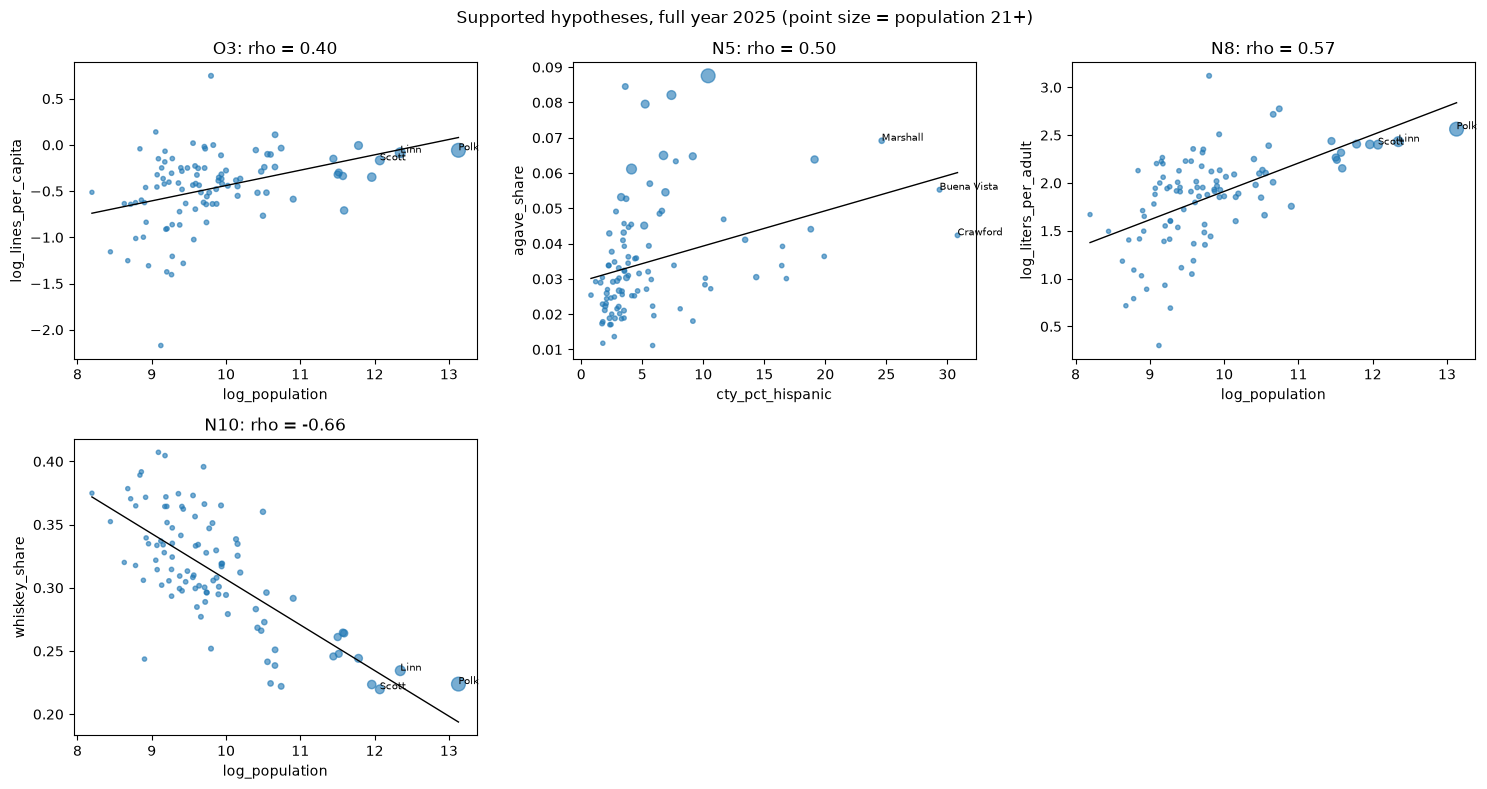

In [18]:
supported = summary.index[summary.verdict == "SUPPORTED"].tolist()
fy = P["FY"]
if supported:
    ncol = min(3, len(supported))
    nrow = int(np.ceil(len(supported) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow), squeeze=False)
    for ax, cid in zip(axes.flat, supported):
        c = CANDIDATES.loc[cid]
        ax.scatter(fy[c.x], fy[c.y], s=fy.cty_population_21_plus / 4000 + 8, alpha=0.6)
        slope, icpt = np.polyfit(fy[c.x], fy[c.y], 1)
        xs = np.linspace(fy[c.x].min(), fy[c.x].max(), 50)
        ax.plot(xs, icpt + slope * xs, color="black", lw=1)
        for _, r in fy.nlargest(3, c.x).iterrows():
            ax.annotate(r.county_name, (r[c.x], r[c.y]), fontsize=7)
        ax.set(xlabel=c.x, ylabel=c.y, title=f"{cid}: rho = {stats.spearmanr(fy[c.x], fy[c.y])[0]:.2f}")
    for ax in axes.flat[len(supported):]:
        ax.axis("off")
    fig.suptitle("Supported hypotheses, full year 2025 (point size = population 21+)")
    plt.tight_layout()

In [19]:
# Multicollinearity among the predictors used in the supported hypotheses (VIF > 5 is a warning sign).
preds = sorted({v for cid in supported for v in [CANDIDATES.loc[cid, "x"]] + CANDIDATES.loc[cid, "controls"]})
if preds:
    Xv = sm.add_constant(fy[preds].apply(z))
    display(pd.Series({p: variance_inflation_factor(Xv.values, i + 1) for i, p in enumerate(preds)}, name="VIF").round(2))

cty_pct_hispanic    1.05
income_k            1.17
log_population      1.21
Name: VIF, dtype: float64

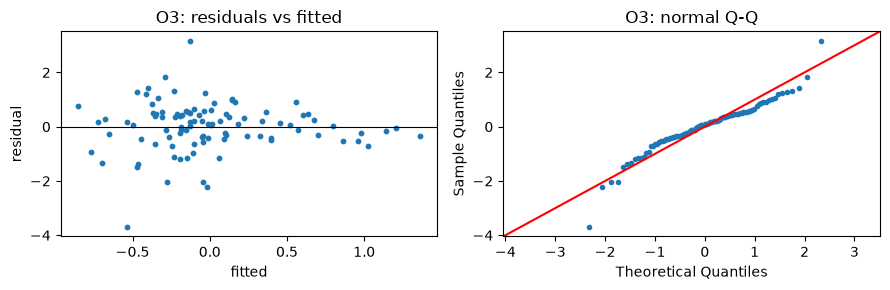

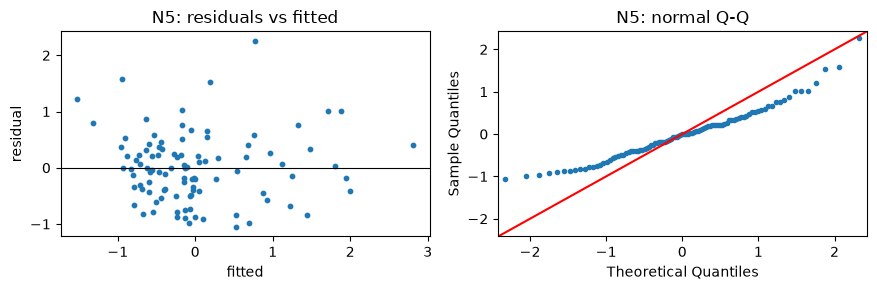

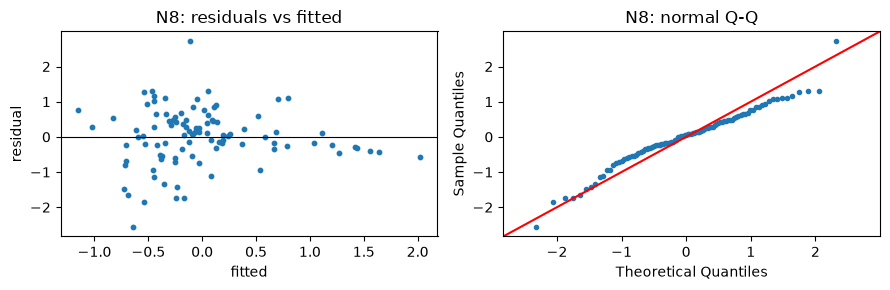

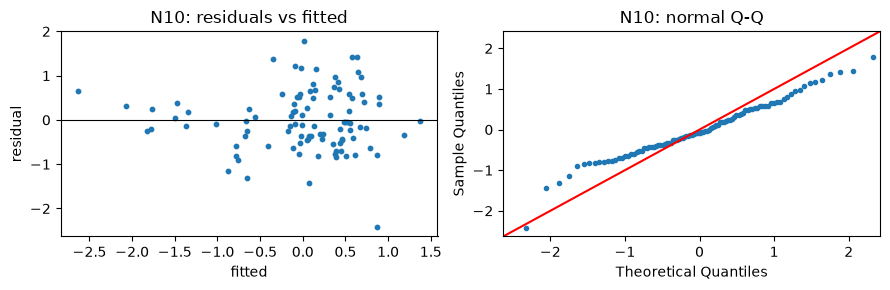

In [20]:
# Residual check for each supported model (full year): residuals vs fitted and a normal Q-Q plot.
for cid in supported:
    c = CANDIDATES.loc[cid]
    fit = ols(fy, c.x, c.y, c.controls)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3))
    a1.scatter(fit.fittedvalues, fit.resid, s=10)
    a1.axhline(0, color="black", lw=0.8)
    a1.set(title=f"{cid}: residuals vs fitted", xlabel="fitted", ylabel="residual")
    sm.qqplot(fit.resid, line="45", ax=a2, markersize=3)
    a2.set_title(f"{cid}: normal Q-Q")
    plt.tight_layout()

## 10. Conclusions for the report

Numbers below are from the run above (seed 2025); β is the standardised OLS coefficient, full year.
Sources: Iowa Liquor Sales 2025 + ACS 5-year 2020–2024 only (the Census Gazetteer was removed, so
county population size replaces population density).

**Keep (supported: screened on Jan–Jun, replicated on Jul–Dec, robust on the full year)**

| Report | Candidate | Result |
|---|---|---|
| **H1a** | N8: larger county population → more liters bought per adult 21+ | ρ = 0.57 / 0.56 (Jan–Jun / Jul–Dec), β = 0.64, 95% CI 0.53 to 0.75 |
| **H1b** | O3 (original H3, kept): larger county population → more order lines per capita | ρ = 0.42 / 0.40, β = 0.47, CI 0.35 to 0.59 |
| **H2** | N5: higher % Hispanic → higher tequila/mezcal share of liters | ρ = 0.50 / 0.47, β = 0.21, CI 0.09 to 0.34 (controls: population, income) |

**Drop (rejected at screening)**
- Original H1 (income → premium liters per adult) and N1 (income → premium *share*): no association (ρ ≈ 0). Income does not explain premium buying across counties. This is a finding worth reporting.
- Original H4 (unemployment → value-tier liters) and N4 (unemployment → value share): not significant after Holm correction. The ACS unemployment estimate is also very uncertain in small counties (median margin of error 39% of the estimate).
- N7 (older counties → lower RTD share): strong raw correlation (ρ = −0.38) that disappears once county size and income are controlled, so it is a proxy for urbanisation, not age.
- Original H2 (% aged 21+ → liters per sq mi) is no longer testable without land area.

**Caveats to state in the report**
- The confirmation period uses the same 99 counties, so it guards against period-specific artefacts (e.g. the duplicated download part or the missing Jan–Jun price columns), not against county-level confounding.
- Sales are **retailer purchases from ABD**, recorded where the store is, not where the drinker lives. Part of H1 is likely cross-county shopping into larger hubs and tourist areas (Dickinson County, the Okoboji lakes, is the top county at 22.7 L per adult; Clinton County borders Illinois).
- H2 is a moderate effect: the two most Hispanic counties (Buena Vista, Crawford) sit below the trend line. Present it with the scatter plot, not the coefficient alone.
- County-level (ecological) associations do not describe individuals.

## 11. Model recommendation: regression vs. classification

The hypothesis tests above already fit **OLS regression** (section 4) because every outcome here
(`liters_per_adult`, `lines_per_capita`, `agave_share`, …) is a **continuous ratio**, which is what
regression is for. The question this section answers is whether a different kind of model — a more
flexible regressor, or reframing the outcome as a **classification** problem (e.g. "is this a
high-agave-demand county?") — would do better, using the three hypotheses that survived screening,
confirmation and robustness (`N8`, `O3`, `N5`).

**Method.** For each supported candidate, same predictor + controls as the hypothesis test, evaluated
with repeated 5-fold cross-validation (`n` = 99, so each fold leaves out ~20 counties):
- **Regression** on the original continuous outcome: Linear Regression, Ridge (shrinkage, helpful if
  predictors are collinear), Random Forest Regressor (captures non-linearity/interactions, no linearity
  assumption). Scored on CV R² and RMSE.
- **Classification** on the outcome split at its median (top half vs. bottom half of counties):
  Logistic Regression, Random Forest Classifier. Scored on CV accuracy and ROC-AUC.

All linear models are fit on standardized predictors via a pipeline; the random-forest models do not
need scaling. This mirrors the OLS already run, just with out-of-sample validation instead of in-sample R².

In [21]:
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

N_SPLITS = 5


def reg_scores(cid):
    c = CANDIDATES.loc[cid]
    d = fy[[c.x, c.y] + c.controls].dropna()
    X, y = d[[c.x] + c.controls].values, d[c.y].values
    cv = KFold(N_SPLITS, shuffle=True, random_state=SEED)
    models = {
        "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=SEED)),
        "RandomForestRegressor": RandomForestRegressor(n_estimators=300, max_depth=3, random_state=SEED),
    }
    rows = []
    for name, m in models.items():
        r2 = cross_val_score(m, X, y, cv=cv, scoring="r2")
        rmse = -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error")
        rows.append(dict(model=name, cv_r2=r2.mean(), cv_r2_std=r2.std(), cv_rmse=rmse.mean()))
    return pd.DataFrame(rows).set_index("model")


def clf_scores(cid):
    c = CANDIDATES.loc[cid]
    d = fy[[c.x, c.y] + c.controls].dropna()
    X = d[[c.x] + c.controls].values
    y_bin = (d[c.y] > d[c.y].median()).astype(int).values
    cv = StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)
    models = {
        "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
        "RandomForestClassifier": RandomForestClassifier(n_estimators=300, max_depth=3, random_state=SEED),
    }
    rows = []
    for name, m in models.items():
        acc = cross_val_score(m, X, y_bin, cv=cv, scoring="accuracy")
        auc = cross_val_score(m, X, y_bin, cv=cv, scoring="roc_auc")
        rows.append(dict(model=name, cv_accuracy=acc.mean(), cv_auc=auc.mean()))
    return pd.DataFrame(rows).set_index("model")


reg_results = {cid: reg_scores(cid) for cid in supported}
clf_results = {cid: clf_scores(cid) for cid in supported}
for cid in supported:
    print(f"{cid}: {CANDIDATES.loc[cid, 'statement']}")
    print("  regression (continuous outcome, 5-fold CV):")
    display(reg_results[cid].round(3))
    print("  classification (outcome split at its median, 5-fold CV):")
    display(clf_results[cid].round(3))

O3: Larger county population -> more transactions (lines) per capita
  regression (continuous outcome, 5-fold CV):


,cv_r2,cv_r2_std,cv_rmse
model,,,
LinearRegression,0.122,0.139,0.365
Ridge,0.123,0.135,0.365
RandomForestRegressor,-0.051,0.417,0.389


  classification (outcome split at its median, 5-fold CV):


,cv_accuracy,cv_auc
model,,
LogisticRegression,0.647,0.738
RandomForestClassifier,0.607,0.682


N5: Higher % Hispanic -> higher tequila/mezcal share of liters
  regression (continuous outcome, 5-fold CV):


...

,cv_accuracy,cv_auc
model,,
LogisticRegression,0.688,0.743
RandomForestClassifier,0.607,0.702


N10: Smaller county population -> higher whiskey share of liters (stocking mix, for ABD)
  regression (continuous outcome, 5-fold CV):


,cv_r2,cv_r2_std,cv_rmse
model,,,
LinearRegression,0.466,0.199,0.032
Ridge,0.467,0.194,0.032
RandomForestRegressor,0.426,0.205,0.033


  classification (outcome split at its median, 5-fold CV):


,cv_accuracy,cv_auc
model,,
LogisticRegression,0.697,0.794
RandomForestClassifier,0.667,0.762


## 12. Recommendation

Results from the run above (seed 2025, 5-fold CV):

| Candidate | LinearRegression CV R² | Ridge CV R² | RandomForest CV R² | LogisticReg CV AUC | RandomForest CV AUC |
|---|---|---|---|---|---|
| N8 (population → liters/adult) | 0.326 | 0.327 | 0.240 | 0.743 | 0.702 |
| O3 (population → lines/capita) | 0.122 | 0.123 | −0.051 | 0.738 | 0.682 |
| N5 (% Hispanic → agave share)  | 0.545 | 0.546 | 0.512 | 0.803 | 0.850 |

**Use regression, not classification, as the primary model.** Every outcome here is naturally
continuous (liters per adult, a share of liters), and the report's claims ("more population → more
liters per adult") are about *direction and magnitude of a continuous effect*, which only a regression
coefficient expresses. Classification (county above/below the median) throws that magnitude away and
answers a narrower, different question. Recommend it as a *secondary, illustrative* model only if the
report wants a plain "which counties look like high-demand counties" segmentation.

**Within regression, prefer plain/Ridge linear regression over Random Forest.** Ridge matches or
slightly beats Linear Regression everywhere (negligible difference — the predictors are not collinear
enough for shrinkage to matter, consistent with the VIF check in section 9) and both **beat Random
Forest on every candidate**, including a negative CV R² for the forest on O3 (worse than predicting the
mean). With only 99 counties and 2-3 predictors, a tree ensemble has nothing to gain from modelling
non-linearity it does not need and every chance to overfit on folds of ~20 counties; a linear model
with few parameters is the better-matched tool. This also keeps the model consistent with the
hypothesis-testing OLS already run in section 4 — same functional form, now validated out-of-sample
instead of only in-sample.

**If a classifier is wanted anyway** (e.g. "flag high-agave-demand counties for targeted stocking"):
Logistic Regression is the safer default for the same small-n/interpretability reasons, except for N5
where Random Forest's CV AUC (0.850) is meaningfully ahead of Logistic Regression's (0.803) — the
%Hispanic → agave relationship has enough non-linearity (visible in the N5 panel of section 9's
scatter plot) that a few shallow trees pick up signal a linear decision boundary misses. Even there,
report Logistic Regression's coefficient for interpretability and mention the Random Forest result only
as a secondary robustness check, not the headline model.